# SHL Hiring Assessment 2026 — Spoken Grammar Scoring Engine (v3)

In [1]:
# ---- Installs (Kaggle: turn Internet ON in Settings, and select a GPU) ----
!pip -q install faster-whisper language-tool-python sentence-transformers

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 22.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 63.2/63.2 kB 3.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.0/35.0 MB 56.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 39.6/39.6 MB 43.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.6/23.6 MB 61.3 MB/s eta 0:00:00


In [2]:
import os, re, json, glob, warnings, difflib, numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from tqdm.auto import tqdm
from scipy.stats import pearsonr
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import mean_squared_error
warnings.filterwarnings("ignore"); sns.set_theme(style="whitegrid")
SEED = 42; np.random.seed(SEED)

# ---- Paths: locate the dataset automatically ----
# Competition input layout: /kaggle/input/<...>/shl-hiring-assessment-2026/Dataset_Final/{train/,test/,train.csv,test.csv,sample_submission.csv}
cands = [os.path.dirname(p) for p in glob.glob("/kaggle/input/**/train.csv", recursive=True)]
BASE = next((c for c in cands if os.path.isdir(f"{c}/train") and os.path.isdir(f"{c}/test")), None)
if BASE is None:
    raise FileNotFoundError(f"Could not find Dataset_Final (train.csv + train/ + test/). Candidates seen: {cands}")
print("BASE =", BASE)
TRAIN_DIR, TEST_DIR = f"{BASE}/train", f"{BASE}/test"
WORK = "/kaggle/working" if os.path.exists("/kaggle/working") else "."

train = pd.read_csv(f"{BASE}/train.csv"); test = pd.read_csv(f"{BASE}/test.csv")
train["path"] = TRAIN_DIR + "/" + train.filename      # train/ and test/ are numbered independently,
test["path"]  = TEST_DIR  + "/" + test.filename       # so always resolve inside the correct split folder
assert train.path.map(os.path.exists).all() and test.path.map(os.path.exists).all(), "missing wavs"
print(train.shape, test.shape)

BASE = /kaggle/input/competitions/shl-hiring-assessment-2026/Dataset_Final
(769, 3) (216, 3)


## 1. Data & EDA

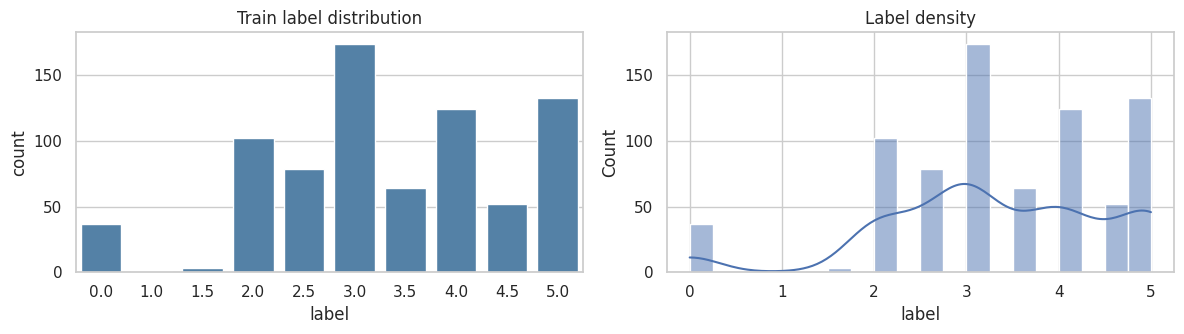

count    769.000000
mean       3.313394
std        1.239000
min        0.000000
25%        2.500000
50%        3.000000
75%        4.000000
max        5.000000
Name: label, dtype: float64


In [3]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
sns.countplot(x=train.label, ax=ax[0], color="steelblue"); ax[0].set_title("Train label distribution")
sns.histplot(train.label, bins=20, kde=True, ax=ax[1]); ax[1].set_title("Label density")
plt.tight_layout(); plt.show(); print(train.label.describe())

Labels sit on a 0.5 grid, mostly 2–5. 37 clips are scored **0** with almost none at 1 — likely silent / unintelligible recordings, which the confidence and word-count features can detect.

## 2. Speech → text with two Whisper models
`faster-whisper` returns word timestamps and probabilities. An `initial_prompt` containing fillers makes Whisper keep “um/uh” and repetitions (evidence of fluency). Audio is loaded with `librosa` (avoids a PyAV version clash). Transcription **checkpoints every 50 clips**, so an interrupted session resumes instead of restarting.

In [4]:
import torch, librosa
from faster_whisper import WhisperModel
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
CT = "float16" if DEVICE == "cuda" else "int8"
print("device:", DEVICE)
PROMPT = "Umm, let me think like, hmm... Okay, here's what I'm, like, thinking. Uh, so I I was going to say"

def transcribe(model, path):
    audio, _ = librosa.load(path, sr=16000, mono=True)
    kw = dict(language="en", beam_size=5, initial_prompt=PROMPT, condition_on_previous_text=False)
    words, seg_lp = [], []
    try:                                              # normal path: word-level timestamps
        segs, info = model.transcribe(audio, word_timestamps=True, **kw)
        for s in segs:
            seg_lp.append((s.avg_logprob, s.no_speech_prob))
            for w in (s.words or []):
                words.append((w.word.strip(), float(w.start), float(w.end), float(w.probability)))
    except Exception:                                 # word alignment can crash on odd clips -> segment-level fallback
        words, seg_lp = [], []
        segs, info = model.transcribe(audio, word_timestamps=False, **kw)
        for s in segs:
            seg_lp.append((s.avg_logprob, s.no_speech_prob))
            toks = s.text.split()
            if not toks: continue
            step, pr = (s.end - s.start) / len(toks), float(np.exp(s.avg_logprob))
            for i, t in enumerate(toks):              # spread words evenly over the segment
                words.append((t, float(s.start + i * step), float(s.start + (i + 1) * step), pr))
    return dict(text=" ".join(w[0] for w in words), words=words, seg_lp=seg_lp, duration=float(len(audio)/16000))

def transcribe_all(model, df, cache):
    if os.path.exists(cache): return json.load(open(cache))
    part = cache + ".part"
    out = json.load(open(part)) if os.path.exists(part) else {}
    for i, p in enumerate(tqdm(df.path, desc=os.path.basename(cache))):
        if p in out: continue
        out[p] = transcribe(model, p)
        if (i + 1) % 50 == 0: json.dump(out, open(part, "w"))
    json.dump(out, open(cache, "w")); return out

# --- pass 1: Whisper small ---
asr_s = WhisperModel("small", device=DEVICE, compute_type=CT)
A1_tr = transcribe_all(asr_s, train, f"{WORK}/asr_train.json")
A1_te = transcribe_all(asr_s, test,  f"{WORK}/asr_test.json")
del asr_s; torch.cuda.empty_cache()

device: cuda


asr_train.json:   0%|          | 0/769 [00:00<?, ?it/s]

asr_test.json:   0%|          | 0/216 [00:00<?, ?it/s]

In [5]:
# --- pass 2: stronger model (distil-large-v3 ~ large-v3 accuracy, much faster). Falls back to medium.en ---
BIG = "distil-large-v3"
try:
    asr_b = WhisperModel(BIG, device=DEVICE, compute_type=CT)
except Exception as e:
    print("could not load", BIG, "->", e, "\nfalling back to medium.en"); BIG = "medium.en"
    asr_b = WhisperModel(BIG, device=DEVICE, compute_type=CT)
print("second ASR model:", BIG)
A2_tr = transcribe_all(asr_b, train, f"{WORK}/asr2_train.json")
A2_te = transcribe_all(asr_b, test,  f"{WORK}/asr2_test.json")
del asr_b; torch.cuda.empty_cache()

train["text1"] = train.path.map(lambda p: A1_tr[p]["text"]); test["text1"] = test.path.map(lambda p: A1_te[p]["text"])
train["text2"] = train.path.map(lambda p: A2_tr[p]["text"]); test["text2"] = test.path.map(lambda p: A2_te[p]["text"])
train[["filename","label","text1","text2"]].sample(4, random_state=1)

second ASR model: distil-large-v3


asr2_train.json:   0%|          | 0/769 [00:00<?, ?it/s]

asr2_test.json:   0%|          | 0/216 [00:00<?, ?it/s]

,filename,label,text1,text2
285,audio_90.wav,4.0,"The most enchanting schools always have large,...",The most interesting schools always have large...
101,audio_430.wav,4.0,My favorite hobby is always listening to music...,My favorite hobby is always listening to music...
582,audio_5071.wav,0.0,"Oh, it's like a comic book. Um, I think it's a...","So, it was a bit of fun of the country. And it..."
352,audio_75.wav,2.0,the topic is describe your stay at a resort. S...,The topic is describe your stay at a resort. S...


## 3. Feature engineering
### 3a. Fluency / timing features (from word timings), computed for both ASR passes

In [6]:
FILLERS = {"um","umm","uh","uhh","er","erm","ah","hmm","hm","mm"}
FLU_KEYS = ["speech_rate","articulation_rate","n_pauses","pause_ratio","mean_pause","max_pause","n_long_pauses",
            "mean_wprob","min_wprob","std_wprob","frac_low_conf","filler_rate","repeat_rate",
            "mean_seg_logprob","mean_no_speech","lead_silence","trail_silence"]

def fluency_feats(r):
    w = r["words"]; dur = max(r["duration"], 1e-6)
    f = {"duration": dur, "n_words": len(w)}
    if len(w) < 2:                                    # (near-)silent clip
        f.update({k: 0.0 for k in FLU_KEYS})
        f["mean_no_speech"] = np.mean([s[1] for s in r["seg_lp"]]) if r["seg_lp"] else 1.0
        return f
    txt = [re.sub(r"[^\w']", "", x[0].lower()) for x in w]
    st = np.array([x[1] for x in w]); en = np.array([x[2] for x in w]); pr = np.array([x[3] for x in w])
    gaps = np.clip(st[1:] - en[:-1], 0, None); pauses = gaps[gaps > 0.25]
    speech_time = max(en[-1] - st[0], 1e-6)
    f.update(
        speech_rate=len(w)/dur, articulation_rate=len(w)/max(speech_time - pauses.sum(), 1e-6),
        n_pauses=len(pauses), pause_ratio=pauses.sum()/speech_time,
        mean_pause=pauses.mean() if len(pauses) else 0, max_pause=gaps.max(), n_long_pauses=int((gaps > 1.0).sum()),
        mean_wprob=pr.mean(), min_wprob=pr.min(), std_wprob=pr.std(), frac_low_conf=(pr < 0.5).mean(),
        filler_rate=sum(t in FILLERS for t in txt)/len(w),
        repeat_rate=sum(a == b and a != "" for a, b in zip(txt[:-1], txt[1:]))/len(w),
        mean_seg_logprob=np.mean([s[0] for s in r["seg_lp"]]), mean_no_speech=np.mean([s[1] for s in r["seg_lp"]]),
        lead_silence=st[0], trail_silence=dur - en[-1])
    return f

def flu_df(asr, df): return pd.DataFrame([fluency_feats(asr[p]) for p in df.path])
flu1_tr, flu1_te = flu_df(A1_tr, train), flu_df(A1_te, test)
flu2_tr, flu2_te = flu_df(A2_tr, train), flu_df(A2_te, test)

# --- agreement between the two transcripts (a robust 'is this speech clear?' signal) ---
def toks(t): return re.findall(r"[a-z']+", t.lower())
def agreement(t1, t2):
    a, b = toks(t1), toks(t2)
    if not a and not b: return dict(asr_agree=1.0, asr_len_ratio=1.0, asr_agree_unigram=1.0)
    sm = difflib.SequenceMatcher(None, a, b, autojunk=False).ratio()
    ua, ub = set(a), set(b)
    return dict(asr_agree=sm, asr_len_ratio=len(b)/max(len(a), 1), asr_agree_unigram=len(ua & ub)/max(len(ua | ub), 1))
agr_tr = pd.DataFrame([agreement(a, b) for a, b in zip(train.text1, train.text2)])
agr_te = pd.DataFrame([agreement(a, b) for a, b in zip(test.text1, test.text2)])
agr_tr.describe().T[["mean","std","min","max"]].round(3)

,mean,std,min,max
asr_agree,0.894,0.130,0.036,1.000
asr_len_ratio,1.030,0.193,0.688,5.346
asr_agree_unigram,0.851,0.145,0.093,1.000


### 3b. Linguistic-quality features (computed on both transcripts)
GPT-2 perplexity (broken grammar is less probable), LanguageTool grammar-rule errors (needs Java; falls back to 0), and surface statistics (sentence length, lexical diversity, subordination as a proxy for complex grammar).

In [7]:
from transformers import AutoTokenizer, AutoModelForCausalLM
gtok = AutoTokenizer.from_pretrained("gpt2"); glm = AutoModelForCausalLM.from_pretrained("gpt2").to(DEVICE).eval()

@torch.no_grad()
def nll(sentence):
    ids = gtok(gtok.bos_token + sentence, return_tensors="pt", truncation=True, max_length=128).input_ids.to(DEVICE)
    if ids.shape[1] < 3: return np.nan
    return glm(ids, labels=ids).loss.item()

try:
    import language_tool_python
    LT = language_tool_python.LanguageTool("en-US")
except Exception as e:
    print("LanguageTool unavailable -> grammar-rule features set to 0:", e); LT = None

SUBORD = {"because","although","though","while","whereas","which","who","whom","whose","that","if","unless","since","when","after","before","until","however","therefore","moreover"}

def ling_feats(text):
    tk = re.findall(r"[A-Za-z']+", text.lower()); n = len(tk)
    sents = [s.strip() for s in re.split(r"(?<=[.!?])\s+", text) if len(s.split()) > 0]
    f = {"n_sents": len(sents), "avg_sent_len": n/max(len(sents),1), "ttr": len(set(tk))/max(n,1), "n_unique": len(set(tk)),
         "avg_word_len": np.mean([len(t) for t in tk]) if n else 0, "subord_rate": sum(t in SUBORD for t in tk)/max(n,1),
         "short_sent_frac": np.mean([len(s.split()) < 4 for s in sents]) if sents else 1}
    nl = [x for x in (nll(s) for s in sents[:40]) if not np.isnan(x)]
    f.update(ppl_mean=np.mean(nl) if nl else 8, ppl_max=np.max(nl) if nl else 8, ppl_std=np.std(nl) if nl else 0,
             ppl_full=nll(text) if n > 2 else 8)
    if LT and n > 2:
        m = LT.check(text)
        gram = [x for x in m if x.category not in ("TYPOS","PUNCTUATION","TYPOGRAPHY","CASING","STYLE")]
        f.update(lt_err_rate=len(m)/n, lt_gram_rate=len(gram)/n, lt_gram_cnt=len(gram))
    else:
        f.update(lt_err_rate=0, lt_gram_rate=0, lt_gram_cnt=0)
    return f

def cached_feats(texts, cache):
    if os.path.exists(cache): return pd.read_csv(cache)
    df = pd.DataFrame([ling_feats(t) for t in tqdm(texts, desc=os.path.basename(cache))]); df.to_csv(cache, index=False); return df

ling1_tr = cached_feats(train.text1, f"{WORK}/ling_train.csv");  ling1_te = cached_feats(test.text1, f"{WORK}/ling_test.csv")
ling2_tr = cached_feats(train.text2, f"{WORK}/ling2_train.csv"); ling2_te = cached_feats(test.text2, f"{WORK}/ling2_test.csv")

X_tr = pd.concat([flu1_tr, ling1_tr, flu2_tr.add_suffix("_b"), ling2_tr.add_suffix("_b"), agr_tr], axis=1)
X_te = pd.concat([flu1_te, ling1_te, flu2_te.add_suffix("_b"), ling2_te.add_suffix("_b"), agr_te], axis=1)
print("hand-crafted feature matrix:", X_tr.shape)

config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

...

`loss_type=None` was set in the config but it is unrecognized. Using the default loss: `ForCausalLMLoss`.


ling_test.csv:   0%|          | 0/216 [00:00<?, ?it/s]

ling2_train.csv:   0%|          | 0/769 [00:00<?, ?it/s]

ling2_test.csv:   0%|          | 0/216 [00:00<?, ?it/s]

hand-crafted feature matrix: (769, 69)


### 3c. Transcript embeddings (both transcripts)

In [8]:
from sentence_transformers import SentenceTransformer
st_model = SentenceTransformer("all-mpnet-base-v2", device=DEVICE)
enc = lambda s: st_model.encode(s.tolist(), batch_size=32, show_progress_bar=False, normalize_embeddings=True)
E1_tr, E1_te, E2_tr, E2_te = enc(train.text1), enc(test.text1), enc(train.text2), enc(test.text2)
print(E1_tr.shape, E2_tr.shape)

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/571 [00:00<?, ?B/s]

...

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

(769, 768) (769, 768)


### 3d. Audio embeddings (wav2vec2)
Text alone cannot see how speech *sounds*. A pretrained wav2vec2 model gives frame-level representations; mean-pooling a middle layer (more acoustic/phonetic) and the last layer, plus the temporal std of the middle layer (captures variability / hesitation), yields a fixed-length vector per clip. Cached to disk.

In [9]:
from transformers import AutoFeatureExtractor, AutoModel
W2V = "facebook/wav2vec2-base-960h"
fe = AutoFeatureExtractor.from_pretrained(W2V); w2v = AutoModel.from_pretrained(W2V).to(DEVICE).eval()

@torch.no_grad()
def audio_emb(path):
    a, _ = librosa.load(path, sr=16000, mono=True)
    x = fe(a, sampling_rate=16000, return_tensors="pt").input_values.to(DEVICE)
    with torch.autocast("cuda", dtype=torch.float16, enabled=(DEVICE == "cuda")):
        hs = w2v(x, output_hidden_states=True).hidden_states
    v = torch.cat([hs[6].float().mean(1), hs[12].float().mean(1), hs[6].float().std(1)], dim=1)
    return v.squeeze(0).cpu().numpy()

def audio_all(df, cache):
    if os.path.exists(cache): return np.load(cache)
    arr = np.stack([audio_emb(p) for p in tqdm(df.path, desc=os.path.basename(cache))]); np.save(cache, arr); return arr
AE_tr = audio_all(train, f"{WORK}/w2v_train.npy"); AE_te = audio_all(test, f"{WORK}/w2v_test.npy")
del w2v; torch.cuda.empty_cache(); print(AE_tr.shape)

preprocessor_config.json:   0%|          | 0.00/159 [00:00<?, ?B/s]

config.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/378M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/210 [00:00<?, ?it/s]

Wav2Vec2Model LOAD REPORT from: facebook/wav2vec2-base-960h
Key               | Status     | 
------------------+------------+-
lm_head.bias      | UNEXPECTED | 
lm_head.weight    | UNEXPECTED | 
masked_spec_embed | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


w2v_train.npy:   0%|          | 0/769 [00:00<?, ?it/s]

w2v_test.npy:   0%|          | 0/216 [00:00<?, ?it/s]

(769, 2304)


### 3e. Two more audio representations
* **WavLM-base-plus** — trained with denoising + masked prediction, strong on paralinguistic / speaker / prosody tasks. Mean of layers 3, 6, 9, 12 plus the temporal std of layer 6.
* **Whisper-small encoder** — an encoder trained on 680k hours of speech; clips longer than 30 s are processed in 30 s windows and averaged. Mean of layers 6 and 12.

Both are cached to disk.

In [10]:
from transformers import WhisperFeatureExtractor, WhisperModel as HFWhisper

def emb_all(fn, df, cache):
    if os.path.exists(cache): return np.load(cache)
    arr = np.stack([fn(p) for p in tqdm(df.path, desc=os.path.basename(cache))]); np.save(cache, arr); return arr

AC = dict(device_type="cuda", dtype=torch.float16, enabled=(DEVICE == "cuda"))

# ---------- WavLM ----------
WL = "microsoft/wavlm-base-plus"
fe_wl = AutoFeatureExtractor.from_pretrained(WL); wavlm = AutoModel.from_pretrained(WL).to(DEVICE).eval()

@torch.no_grad()
def wavlm_emb(path):
    a, _ = librosa.load(path, sr=16000, mono=True)
    x = fe_wl(a, sampling_rate=16000, return_tensors="pt").input_values.to(DEVICE)
    with torch.autocast(**AC):
        hs = wavlm(x, output_hidden_states=True).hidden_states
    v = torch.cat([hs[l].float().mean(1) for l in (3, 6, 9, 12)] + [hs[6].float().std(1)], dim=1)
    return v.squeeze(0).cpu().numpy()

WLm_tr = emb_all(wavlm_emb, train, f"{WORK}/wavlm_train.npy"); WLm_te = emb_all(wavlm_emb, test, f"{WORK}/wavlm_test.npy")
del wavlm; torch.cuda.empty_cache(); print("WavLM:", WLm_tr.shape)

# ---------- Whisper encoder ----------
WE = "openai/whisper-small"
fe_we = WhisperFeatureExtractor.from_pretrained(WE); wenc = HFWhisper.from_pretrained(WE).get_encoder().to(DEVICE).eval()

@torch.no_grad()
def whisper_enc_emb(path):
    a, _ = librosa.load(path, sr=16000, mono=True)
    chunks = [a[i:i + 480000] for i in range(0, max(len(a), 1), 480000)]          # 30 s windows
    if len(chunks) > 1 and len(chunks[-1]) < 16000: chunks = chunks[:-1]           # drop <1 s tail
    outs, ws = [], []
    for c in chunks:
        f = fe_we(c, sampling_rate=16000, return_tensors="pt").input_features.to(DEVICE)
        with torch.autocast(**AC):
            hs = wenc(f, output_hidden_states=True).hidden_states
        nv = max(1, min(1500, int(np.ceil(len(c) / 16000 * 50))))                   # 50 encoder frames / s, ignore padding
        outs.append(torch.cat([hs[6][0, :nv].float().mean(0), hs[12][0, :nv].float().mean(0)]).cpu().numpy()); ws.append(len(c))
    return np.average(outs, axis=0, weights=ws)

WEn_tr = emb_all(whisper_enc_emb, train, f"{WORK}/wenc_train.npy"); WEn_te = emb_all(whisper_enc_emb, test, f"{WORK}/wenc_test.npy")
del wenc; torch.cuda.empty_cache(); print("Whisper encoder:", WEn_tr.shape)

preprocessor_config.json:   0%|          | 0.00/215 [00:00<?, ?B/s]

config.json: 0.00B [00:00, ?B/s]

pytorch_model.bin:   0%|          | 0.00/378M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/248 [00:00<?, ?it/s]

wavlm_train.npy:   0%|          | 0/769 [00:00<?, ?it/s]

...

model.safetensors:   0%|          | 0.00/967M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/479 [00:00<?, ?it/s]

wenc_train.npy:   0%|          | 0/769 [00:00<?, ?it/s]

wenc_test.npy:   0%|          | 0/216 [00:00<?, ?it/s]

Whisper encoder: (769, 1536)


### Feature ↔ target correlation (interpretability)

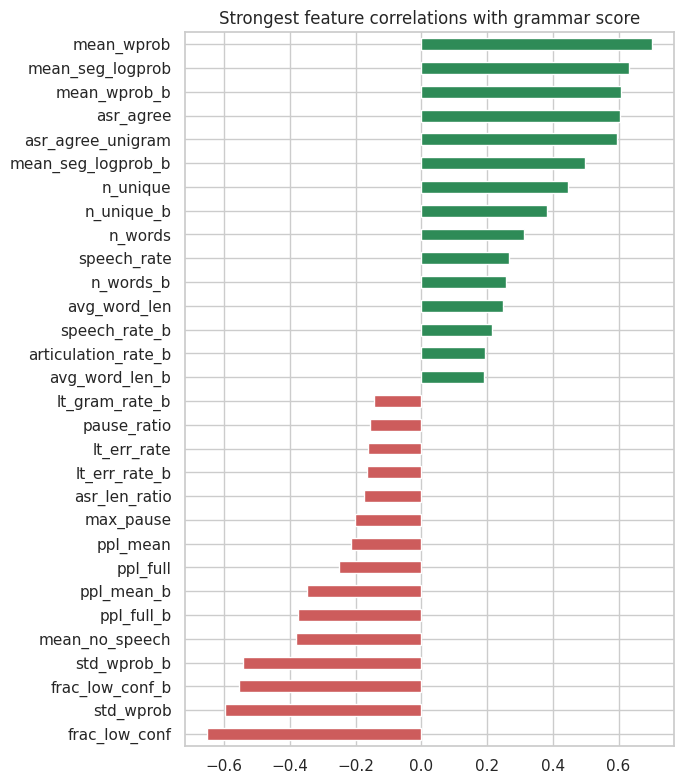

In [11]:
corr = X_tr.assign(label=train.label).corr(numeric_only=True)["label"].drop("label").sort_values()
top = pd.concat([corr.head(15), corr.tail(15)])
plt.figure(figsize=(7,8)); top.plot.barh(color=np.where(top>0,"seagreen","indianred"))
plt.title("Strongest feature correlations with grammar score"); plt.tight_layout(); plt.show()

## 4. The zero-score block, and the gate
All 37 clips labelled 0 are files `audio_5037 … audio_5073`; no other training file has an id above ~770, and **no test file does either**. They are a separate recording group and are trivially separable. Including them in regression training/validation (a) wastes model capacity and (b) inflates CV Pearson/RMSE because they sit at the extreme of the scale. So:

* the **regression models** are trained and validated on clips scored **> 0** only (these resemble the test set);
* a regularised **logistic "gate"** on the hand-crafted features detects zero-type clips; it only overrides the regression when it is very confident (p > 0.9), and its behaviour on the test set is printed so it can be audited.

In [12]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import Ridge, LinearRegression, LogisticRegression
from sklearn.svm import SVR
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.impute import SimpleImputer
from sklearn.model_selection import RepeatedStratifiedKFold

y_all = train.label.values.astype(float)
keep = y_all > 0                        # regression set (matches the test distribution)
y = y_all[keep]
print(f"regression set: {keep.sum()} clips (dropped {(~keep).sum()} zero-block clips)")

Xh_all, Xh_te = X_tr.values.astype(float), X_te.values.astype(float)
blocks_tr = dict(h=Xh_all, E1=E1_tr, E2=E2_tr, w2v=AE_tr, wl=WLm_tr, we=WEn_tr)
blocks_te = dict(h=Xh_te,  E1=E1_te, E2=E2_te, w2v=AE_te, wl=WLm_te, we=WEn_te)
def stack(b, names): return np.hstack([b[n] for n in names])
SETS = {"all":   ["h","E1","E2","w2v","wl","we"],
        "audio": ["w2v","wl","we"],
        "text":  ["h","E1","E2"],
        "hand":  ["h"]}
M_all = {k: stack(blocks_tr, v) for k, v in SETS.items()}      # all 769 rows
M_te  = {k: stack(blocks_te, v) for k, v in SETS.items()}
M     = {k: v[keep] for k, v in M_all.items()}                  # regression rows only
print({k: v.shape for k, v in M.items()})

regression set: 732 clips (dropped 37 zero-block clips)
{'all': (732, 9285), 'audio': (732, 7680), 'text': (732, 1605), 'hand': (732, 69)}


In [13]:
# ---- Gate: is this a zero-type clip? (5-fold OOF check, then fit on everything) ----
is_zero = (~keep).astype(int)
gate = make_pipeline(SimpleImputer(), StandardScaler(), LogisticRegression(C=1.0, class_weight="balanced", max_iter=5000))
p0_oof = np.zeros(len(is_zero))
for tri, vai in StratifiedKFold(5, shuffle=True, random_state=SEED).split(Xh_all, is_zero):
    p0_oof[vai] = gate.fit(Xh_all[tri], is_zero[tri]).predict_proba(Xh_all[vai])[:, 1]
TH = 0.9
print("gate OOF  | zero clips flagged:", int(((p0_oof > TH) & (is_zero == 1)).sum()), "/", int(is_zero.sum()),
      "| non-zero clips wrongly flagged:", int(((p0_oof > TH) & (is_zero == 0)).sum()), "/", int((is_zero == 0).sum()))
gate.fit(Xh_all, is_zero)
p0_in, p0_te = gate.predict_proba(Xh_all)[:, 1], gate.predict_proba(Xh_te)[:, 1]
print("gate on TEST | clips flagged as zero-type:", int((p0_te > TH).sum()), "of", len(p0_te))
if (p0_te > TH).any():
    print("  -> inspect these test files:", test.filename[p0_te > TH].tolist())

gate OOF  | zero clips flagged: 31 / 37 | non-zero clips wrongly flagged: 4 / 732
gate on TEST | clips flagged as zero-type: 2 of 216
  -> inspect these test files: ['audio_107.wav', 'audio_66.wav']


## 5. Regression models
| Model | Input | Why |
|---|---|---|
| Ridge (all) | fluency + linguistic + both text embeddings + 3 audio embeddings | strong, stable linear model for n≈730 |
| Ridge (audio) | wav2vec2 + WavLM + Whisper-encoder embeddings | independent acoustic view |
| Ridge (text) | fluency + linguistic + text embeddings | independent linguistic view |
| SVR | PCA-reduced all features | smooth non-linear model with a different bias |
| HistGradientBoosting | fluency + linguistic features | non-linear interactions |

Hyper-parameters are chosen with 5-fold stratified CV; the final OOF predictions use **3 × repeated 5-fold CV** (each clip is predicted 3 times by models that never saw it) and are blended with non-negative linear weights.

In [14]:
make_ridge = lambda a: make_pipeline(SimpleImputer(), StandardScaler(), Ridge(alpha=a))
make_svr   = lambda C: make_pipeline(SimpleImputer(), StandardScaler(), PCA(96, random_state=SEED), SVR(C=C, epsilon=0.2))
make_gbm   = lambda: HistGradientBoostingRegressor(max_depth=3, learning_rate=0.04, max_iter=400, l2_regularization=1.0,
                                                  min_samples_leaf=15, random_state=SEED)
R = 3
strata = np.round(y).astype(int); strata[strata < 2] = 2
rskf = RepeatedStratifiedKFold(n_splits=5, n_repeats=R, random_state=SEED)
SPLITS = list(rskf.split(np.zeros(len(y)), strata))
rmse = lambda a, b: np.sqrt(mean_squared_error(a, np.clip(b, 0, 5)))

def oof(make, X, reps=R):
    o = np.zeros((reps, len(y)))
    for i, (tri, vai) in enumerate(SPLITS[:reps * 5]):
        o[i // 5, vai] = make().fit(X[tri], y[tri]).predict(X[vai])
    return o

def sweep(name, factory, grid, X):
    sc = {g: rmse(y, oof(lambda: factory(g), X, reps=1)[0]) for g in grid}
    best = min(sc, key=sc.get); print(f"{name:12s} sweep:", {k: round(v, 4) for k, v in sc.items()}, "-> best", best); return best

a_all = sweep("ridge_all",   make_ridge, [300, 1000, 3000, 10000, 30000], M["all"])
a_aud = sweep("ridge_audio", make_ridge, [100, 300, 1000, 3000, 10000],   M["audio"])
a_txt = sweep("ridge_text",  make_ridge, [100, 300, 1000, 3000],          M["text"])
c_svr = sweep("svr (C)",     make_svr,   [0.3, 1, 3],                     M["all"])

SPEC = {  # name: (factory, matrix-key)
    "ridge_all":   (lambda: make_ridge(a_all), "all"),
    "ridge_audio": (lambda: make_ridge(a_aud), "audio"),
    "ridge_text":  (lambda: make_ridge(a_txt), "text"),
    "svr":         (lambda: make_svr(c_svr),   "all"),
    "gbm":         (make_gbm,                  "hand")}
OOF = {k: oof(f, M[key]) for k, (f, key) in SPEC.items()}                       # (R, n) each
O = np.column_stack([v.mean(0) for v in OOF.values()])
blend = LinearRegression(positive=True).fit(O, y)
print("\nblend weights:", dict(zip(OOF, blend.coef_.round(3))), "| intercept", round(blend.intercept_, 3))
o_blend = np.clip(blend.predict(O), 0, 5)
per_rep = [rmse(y, blend.predict(np.column_stack([v[r] for v in OOF.values()]))) for r in range(R)]
for k, v in {**OOF}.items():
    print(f"{k:12s} CV RMSE={rmse(y, v.mean(0)):.4f}  Pearson={pearsonr(y, np.clip(v.mean(0), 0, 5))[0]:.4f}")
print(f"{'BLEND':12s} CV RMSE={rmse(y, o_blend):.4f}  Pearson={pearsonr(y, o_blend)[0]:.4f}   "
      f"(single-repeat RMSE {np.mean(per_rep):.4f} ± {np.std(per_rep):.4f})")

ridge_all    sweep: {300: np.float64(0.548), 1000: np.float64(0.5367), 3000: np.float64(0.5333), 10000: np.float64(0.547), 30000: np.float64(0.5852)} -> best 3000
ridge_audio  sweep: {100: np.float64(0.5552), 300: np.float64(0.5463), 1000: np.float64(0.537), 3000: np.float64(0.5398), 10000: np.float64(0.561)} -> best 1000
ridge_text   sweep: {100: np.float64(0.749), 300: np.float64(0.6927), 1000: np.float64(0.6663), 3000: np.float64(0.6751)} -> best 1000
svr (C)      sweep: {0.3: np.float64(0.5845), 1: np.float64(0.5425), 3: np.float64(0.5334)} -> best 3

blend weights: {'ridge_all': np.float64(0.0), 'ridge_audio': np.float64(0.493), 'ridge_text': np.float64(0.187), 'svr': np.float64(0.313), 'gbm': np.float64(0.11)} | intercept -0.369
ridge_all    CV RMSE=0.5293  Pearson=0.8539
ridge_audio  CV RMSE=0.5308  Pearson=0.8522
ridge_text   CV RMSE=0.6584  Pearson=0.7607
svr          CV RMSE=0.5329  Pearson=0.8515
gbm          CV RMSE=0.6748  Pearson=0.7463
BLEND        CV RMSE=0.5059  Pearso

## 6. Cross-validated diagnostics (clips scored > 0)

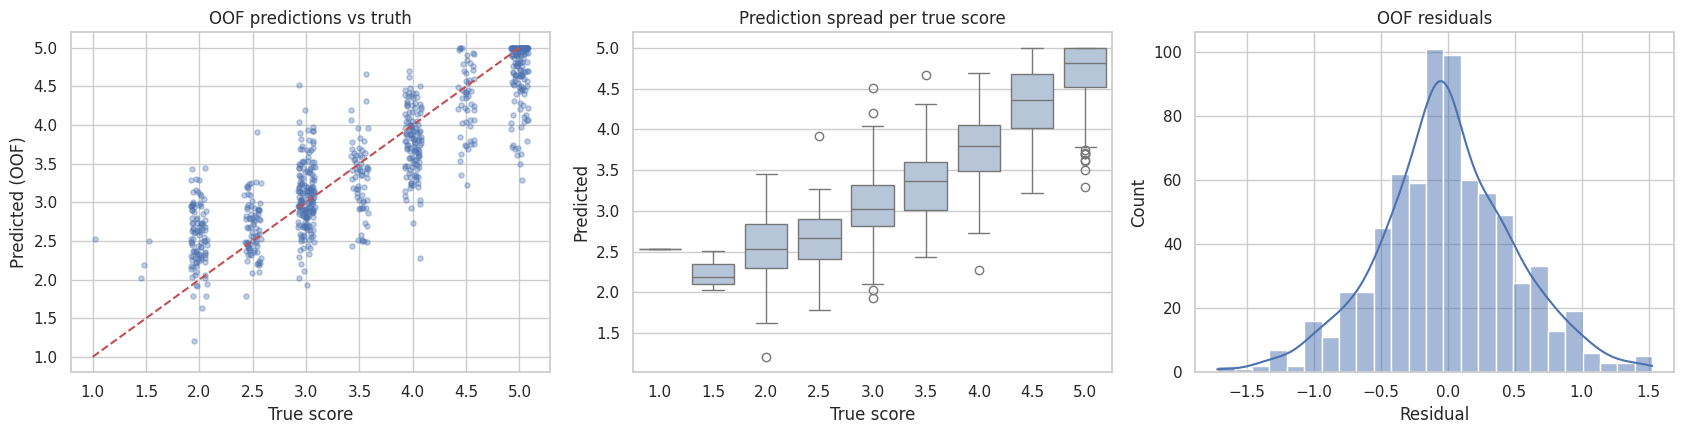

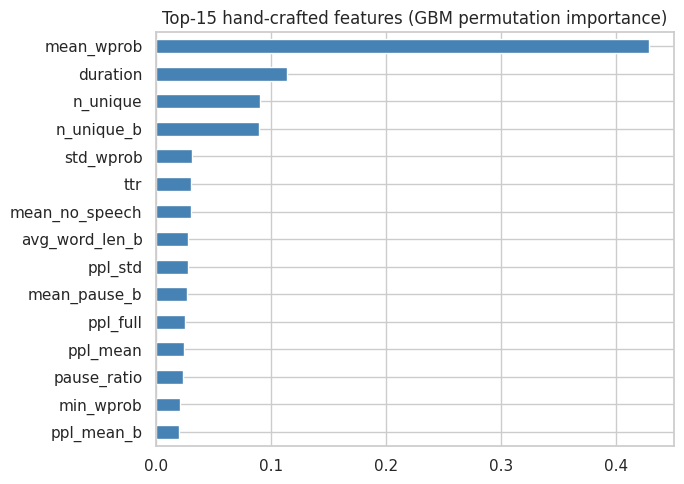

In [15]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
ax[0].scatter(y + np.random.uniform(-.08,.08,len(y)), o_blend, alpha=.35, s=14)
ax[0].plot([1,5],[1,5],"r--"); ax[0].set(xlabel="True score", ylabel="Predicted (OOF)", title="OOF predictions vs truth")
sns.boxplot(x=y, y=o_blend, ax=ax[1], color="lightsteelblue"); ax[1].set(xlabel="True score", ylabel="Predicted", title="Prediction spread per true score")
sns.histplot(o_blend - y, kde=True, ax=ax[2]); ax[2].set(xlabel="Residual", title="OOF residuals")
plt.tight_layout(); plt.show()

from sklearn.inspection import permutation_importance
g = make_gbm().fit(M["hand"], y)
pi = permutation_importance(g, M["hand"], y, n_repeats=8, random_state=SEED, scoring="neg_root_mean_squared_error")
imp = pd.Series(pi.importances_mean, index=X_tr.columns).sort_values().tail(15)
plt.figure(figsize=(7,5)); imp.plot.barh(color="steelblue"); plt.title("Top-15 hand-crafted features (GBM permutation importance)"); plt.tight_layout(); plt.show()

## 7. Final fit on all training data

In [16]:
P_tr, P_te = [], []
for k, (f, key) in SPEC.items():
    m = f().fit(M[key], y)
    P_tr.append(m.predict(M_all[key])); P_te.append(m.predict(M_te[key]))          # P_tr covers ALL 769 train rows
def final(P, p0): return np.where(p0 > TH, 0.0, np.clip(blend.predict(np.column_stack(P)), 0, 5))
train_pred = final(P_tr, p0_in)                    # all 769 training clips (gate handles the zero block)
test_pred  = final(P_te, p0_te)

## 8. Results — RMSE on the training data (required)
The **in-sample (training) RMSE** is what the submission rules ask for; it is reported on all 769 training clips and on the 732 clips scored > 0. The **cross-validated** figure (clips scored > 0, which is what the test set resembles) is the honest estimate of generalisation — in-sample numbers are optimistic because the models have seen those labels.

In [17]:
tr_all_rmse = np.sqrt(mean_squared_error(y_all, train_pred)); tr_all_r = pearsonr(y_all, train_pred)[0]
tr_nz_rmse  = np.sqrt(mean_squared_error(y_all[keep], train_pred[keep])); tr_nz_r = pearsonr(y_all[keep], train_pred[keep])[0]
cv_rmse, cv_r = np.sqrt(mean_squared_error(y, o_blend)), pearsonr(y, o_blend)[0]
summary = pd.DataFrame({"RMSE": [tr_all_rmse, tr_nz_rmse, cv_rmse], "Pearson": [tr_all_r, tr_nz_r, cv_r]},
    index=["TRAIN in-sample (all 769 clips)", "TRAIN in-sample (732 clips scored > 0)", f"{R}x5-fold CV (clips scored > 0)"]).round(4)
print(summary); print(f"\nBaseline RMSE (predict the mean, clips > 0): {y.std():.4f}")
summary

                                          RMSE  Pearson
TRAIN in-sample (all 769 clips)         0.1863   0.9890
TRAIN in-sample (732 clips scored > 0)  0.1909   0.9828
3x5-fold CV (clips scored > 0)          0.5059   0.8669

Baseline RMSE (predict the mean, clips > 0): 1.0137


,RMSE,Pearson
TRAIN in-sample (all 769 clips),0.1863,0.9890
TRAIN in-sample (732 clips scored > 0),0.1909,0.9828
3x5-fold CV (clips scored > 0),0.5059,0.8669


### Comparison with earlier versions

In [18]:
cmp_ = pd.DataFrame({
    "CV RMSE":     [0.7004, 0.5620, 0.5734, cv_rmse],
    "CV Pearson":  [0.8248, 0.8918, 0.8260, cv_r],
    "evaluated on": ["all 769", "all 769", "732 (>0)", "732 (>0)"]},
    index=["v1 (small ASR, text+fluency)", "v2 (2 ASR + wav2vec2, 4 models)  [public LB RMSE 0.4318]",
           "v2, re-scored on clips > 0", "v3 (+WavLM, +Whisper-enc, zero-block gate, repeated CV)"]).round(4)
cmp_

,CV RMSE,CV Pearson,evaluated on
"v1 (small ASR, text+fluency)",0.7004,0.8248,all 769
"v2 (2 ASR + wav2vec2, 4 models) [public LB RMSE 0.4318]",0.5620,0.8918,all 769
"v2, re-scored on clips > 0",0.5734,0.8260,732 (>0)
"v3 (+WavLM, +Whisper-enc, zero-block gate, repeated CV)",0.5059,0.8669,732 (>0)


## 9. Predict test set & write submission

(216, 2) NaNs: 0 {'count': 216.0, 'mean': 3.213, 'std': 0.917, 'min': 0.0, '25%': 2.578, '50%': 3.135, '75%': 3.688, 'max': 5.0}


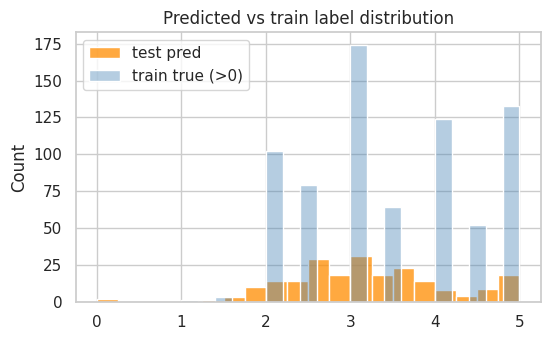

,filename,label
0,audio_128.wav,2.963107
1,audio_156.wav,3.999763
2,audio_19.wav,4.546893
3,audio_108.wav,1.502208
4,audio_206.wav,2.177589


In [19]:
sub = pd.DataFrame({"filename": test.filename, "label": test_pred})
assert len(sub) == 216 and sub.label.notna().all()
sub.to_csv(f"{WORK}/submission.csv", index=False)
print(sub.shape, "NaNs:", sub.label.isna().sum(), sub.label.describe().round(3).to_dict())
plt.figure(figsize=(6,3.5)); sns.histplot(test_pred, bins=20, color="darkorange", label="test pred")
sns.histplot(y_all[keep], bins=20, color="steelblue", alpha=.4, label="train true (>0)"); plt.legend(); plt.title("Predicted vs train label distribution"); plt.show()
sub.head()